# IT3051 Fundamentals of Data Mining — BankReach
## Final Complete Assessment Notebook — Stage 1 to Stage 8

**Project:** BankReach — Term-Deposit Subscription Prediction  
**Group:** InsightX  
**Student:** IT23589940 — Kanakasekara K.A.D.A.L.  
**Course:** IT3051 Fundamentals of Data Mining  
**Dataset:** UCI Bank Marketing — `bank-additional-full.csv` / supplied copy `bank-additional-full(1).csv`

---

### Purpose of this final notebook

This notebook presents a complete, assessment-ready data-mining workflow covering the assessed **Stage 1–Stage 8** activities:

1. **Stage 1 — Understand the Assigned Problem Scenario**
2. **Stage 2 — Dataset Identification and Validation**
3. **Stage 3 — Data Understanding and Exploratory Data Analysis (EDA)**
4. **Stage 4 — Data Preprocessing and Feature Engineering**
5. **Stage 5 — Progress Evaluation 1 / Individual Viva Preparation**
6. **Stage 6 — Model Development**
7. **Stage 7 — Model Optimization and Final Model Selection**
8. **Stage 8 — Progress Evaluation 2 / Individual Viva Preparation**

### Final methodological decision: chronological validation

The official UCI documentation for the selected file states that **`bank-additional-full.csv` contains all 41,188 examples and 20 input variables, ordered by date from May 2008 to November 2010**. The file does not include a year column, so this notebook does **not** attempt to reconstruct an exact year for every row. Instead, it preserves the documented row order and evaluates the model forward in that order.

**Final validation design:**

- **70% earliest observations → training set**
- **15% following observations → validation set**
- **15% latest observations → final test set**
- **TimeSeriesSplit** is used inside model-development cross-validation.
- The raw row order is **never shuffled** for the chronological split.
- All learned transformations stay inside the end-to-end `Pipeline`, preventing fold-level preprocessing leakage.

Repeated month labels such as `may` or `jun` are expected because the dataset spans multiple years. They do **not** imply that the file is randomly ordered. The chronology claim comes from the official UCI dataset documentation rather than from reconstructing missing year values.

**Official source:** UCI Machine Learning Repository, Bank Marketing, Dataset ID 222.  
https://archive.ics.uci.edu/dataset/222/bank  
DOI: `10.24432/C5K306`

> **Execution rule:** Run the notebook from top to bottom. It accepts `bank-additional-full.csv`, the supplied `bank-additional-full(1).csv`, or a Colab upload.

# ============================================================
# STAGE 1 — UNDERSTAND THE ASSIGNED PROBLEM SCENARIO
# ============================================================

## 1.1 Real-world problem

A bank conducts telephone marketing campaigns to promote term deposits. Each additional customer contact consumes staff time and campaign capacity. BankReach is designed as a **decision-support classification system** that estimates the probability that a customer will subscribe to a term deposit, helping campaign staff prioritize outreach.

## 1.2 Prediction objective and target

**Target variable:** `y`

- `yes` → the customer subscribed to the term deposit.
- `no` → the customer did not subscribe.

The data-mining task is **binary classification**.

## 1.3 Stakeholders

Marketing campaign managers, call-center supervisors, relationship teams, business analysts, and ML/data-science teams.

## 1.4 User requirements

The system should accept customer/campaign information available before the current call, produce a subscription probability, apply a documented decision threshold, and expose the result as decision support rather than an automatic final decision.

## 1.5 Expected system inputs and outputs

| Component | Description |
|---|---|
| Inputs | Customer profile, financial/loan indicators, campaign history, current campaign information, and economic context available before a call |
| Model output | Probability of term-deposit subscription |
| Decision output | Binary prioritization flag using a validation-selected threshold |
| Intended use | Prioritize outreach resources and support campaign planning |

## 1.6 Success criteria

Because the positive class is much smaller than the negative class, **Average Precision / PR-AUC** is used as the primary model-comparison metric. F2 is also reported because it weights recall more heavily than precision for the operational threshold decision.

# ============================================================
# STAGE 2 — DATASET IDENTIFICATION AND VALIDATION
# ============================================================

## 2.1 Dataset proposal

**Dataset name:** Bank Marketing Dataset — `bank-additional-full.csv`  
**Original source:** UCI Machine Learning Repository — Bank Marketing, Dataset ID 222  
**Dataset page:** https://archive.ics.uci.edu/dataset/222/bank  
**DOI:** `10.24432/C5K306`  
**Task:** Binary classification of term-deposit subscription.

The official UCI documentation states that `bank-additional-full.csv` contains **41,188 examples and 20 input variables**, and that the full file is **ordered by date from May 2008 to November 2010**. The target variable is `y`, indicating whether the client subscribed to a term deposit.

The dataset is suitable because its observations describe telephone marketing contacts and include customer, campaign-history and economic-context variables that can support the stated prediction problem.

## 2.2 Instructor validation requirement

The IT3051 brief states that the selected public dataset must be shown to and validated by an instructor **before** EDA, preprocessing, model development or system development.

**Submission evidence to attach here:** the instructor/lab validation screenshot, form record, email, or other official evidence of dataset approval.

> **Do not claim instructor approval in this notebook unless you actually have the evidence.** This cell intentionally leaves the evidence as a submission item.

## 2.3 Data-quality and scope considerations

Known limitations include strong target imbalance, explicit `unknown` categories, a sentinel `pdays = 999` value, campaign-history variables with unusual distributions, historical population/context, and the post-contact `duration` feature that would leak information into a pre-call prediction model.

## 2.4 Ethics and responsible use

The dataset is used for academic modelling. A production system should apply data minimization, access control, purpose limitation, monitoring for group-level performance differences, human oversight, and clear disclosure that the prediction is a probabilistic decision-support signal rather than a guaranteed outcome.

## 2.5 Dataset licensing

UCI lists the dataset under **CC BY 4.0**. Any submitted report or presentation should retain appropriate attribution to the dataset source.

In [1]:
# ============================================================
# COMMON IMPORTS AND REPRODUCIBILITY CONFIGURATION
# ============================================================

import os
import json
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import loguniform, randint

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, precision_recall_curve, roc_curve,
    make_scorer
)
from sklearn.feature_selection import SelectPercentile, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_class_weight

import joblib

RANDOM_STATE = 42
TARGET = "y"
LEAKAGE_FEATURES = ["duration"]
np.random.seed(RANDOM_STATE)

print("Environment ready")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Random state:", RANDOM_STATE)

Environment ready
NumPy: 2.3.5
Pandas: 2.2.3
Random state: 42


In [2]:
# ============================================================
# DATASET LOADING
# ============================================================

# Works for the standard filename, the supplied renamed copy, or Colab upload.
candidates = [Path("bank-additional-full.csv"), Path("bank-additional-full(1).csv"), Path("/mnt/data/bank-additional-full(1).csv")]
path = next((p for p in candidates if p.exists()), None)

if path is None:
    try:
        from google.colab import files
        print("Dataset file not found. Please upload the supplied bank-additional-full CSV file.")
        uploaded = files.upload()
        uploaded_names = list(uploaded.keys())
        if not uploaded_names:
            raise FileNotFoundError("No dataset was uploaded.")
        path = Path(uploaded_names[0])
    except ImportError:
        raise FileNotFoundError(
            "Dataset not found. Place bank-additional-full.csv in the notebook folder "
            "or set DATA_PATH to the supplied CSV file."
        )

DATA_PATH = str(path)
df = pd.read_csv(DATA_PATH, sep=";")
df_original = df.copy(deep=True)

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
print("Target column present:", TARGET in df.columns)
print("First 3 rows:")
display(df.head(3))

Loaded: bank-additional-full(1).csv
Shape: (41188, 21)
Target column present: True
First 3 rows:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# ============================================================
# STAGE 3 — DATA UNDERSTANDING & EXPLORATORY DATA ANALYSIS
# ============================================================

The purpose of Stage 3 is to understand structure, variable types, relationships, data quality, unusual observations, class imbalance and potential leakage, then explicitly connect findings to modelling decisions.

In [3]:
# 3.1 Structure, data types and record-level inspection
print("Dataset info:")
df.info()

column_summary = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str),
    "unique_values": [df[c].nunique(dropna=True) for c in df.columns],
    "missing_values": [int(df[c].isna().sum()) for c in df.columns],
})
display(column_summary)

print("Exact duplicate rows:", int(df.duplicated().sum()))
print("True missing cells (NaN only):", int(df.isna().sum().sum()))

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   4

,column,dtype,unique_values,missing_values
age,age,int64,78,0
job,job,object,12,0
marital,marital,object,4,0
education,education,object,8,0
default,default,object,3,0
housing,housing,object,3,0
loan,loan,object,3,0
contact,contact,object,2,0
month,month,object,10,0
day_of_week,day_of_week,object,5,0


Exact duplicate rows: 12
True missing cells (NaN only): 0


In [4]:
# 3.2 Numerical and categorical summaries
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include="object").columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

display(df[numerical_columns].describe().T)

Numerical columns: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


,count
y,
no,36548
yes,4640


,percentage
y,
no,88.73
yes,11.27


Negative class: 36,548
Positive class: 4,640
No/Yes imbalance ratio: 7.88:1


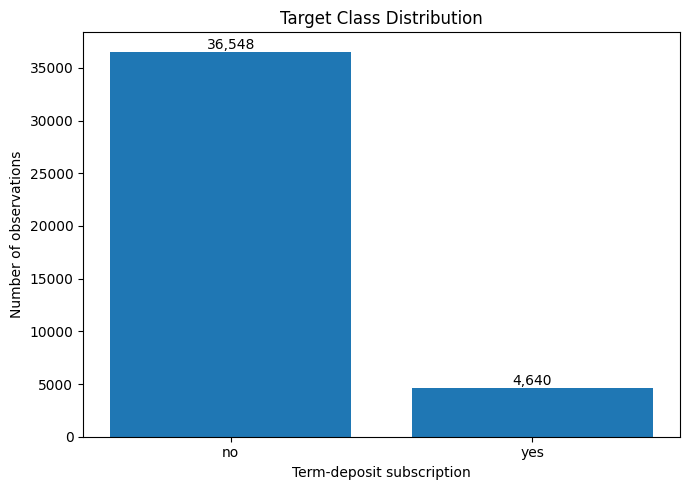

In [5]:
# 3.3 Target distribution and class imbalance
TARGET_COUNTS = df[TARGET].value_counts()
TARGET_PCT = df[TARGET].value_counts(normalize=True).mul(100)

display(TARGET_COUNTS.rename("count").to_frame())
display(TARGET_PCT.rename("percentage").round(2).to_frame())

negative = int((df[TARGET] == "no").sum())
positive = int((df[TARGET] == "yes").sum())
imbalance_ratio = negative / positive

print(f"Negative class: {negative:,}")
print(f"Positive class: {positive:,}")
print(f"No/Yes imbalance ratio: {imbalance_ratio:.2f}:1")

plt.figure(figsize=(7,5))
counts = TARGET_COUNTS.reindex(["no", "yes"])
plt.bar(counts.index, counts.values)
plt.title("Target Class Distribution")
plt.xlabel("Term-deposit subscription")
plt.ylabel("Number of observations")
for i,v in enumerate(counts.values):
    plt.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

### Interpretation — target imbalance

The positive class is a minority class. Accuracy alone could therefore be misleading because a model can obtain high accuracy by heavily favoring the majority class. This motivates PR-AUC, ROC-AUC, balanced accuracy, precision, recall, F1 and F2 reporting.

In [6]:
# 3.4 Missing values and explicit 'unknown' categories
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean().mul(100).round(3)
}).sort_values("missing_count", ascending=False)
display(missing_summary)

unknown_rows = []
for col in categorical_columns:
    count = int((df[col] == "unknown").sum())
    if count:
        unknown_rows.append({
            "Feature": col,
            "Unknown count": count,
            "Unknown %": 100 * count / len(df)
        })
unknown_df = pd.DataFrame(unknown_rows).sort_values("Unknown count", ascending=False)
display(unknown_df)

,missing_count,missing_percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
month,0,0.0
day_of_week,0,0.0


,Feature,Unknown count,Unknown %
3,default,8597,20.872584
2,education,1731,4.202680
4,housing,990,2.403613
5,loan,990,2.403613
0,job,330,0.801204
1,marital,80,0.194231


### Interpretation — missing and `unknown`

The file contains no true NaN cells in the supplied copy, but several categorical fields contain the explicit value `unknown`. `unknown` is preserved because it is an observed category rather than an automatically missing row. The pipeline still contains imputers so it remains robust if future prediction inputs contain missing values.

In [7]:
# 3.5 Duplicate analysis
duplicate_count = int(df.duplicated().sum())
print("Exact duplicate count:", duplicate_count)
print("Exact duplicate percentage:", round(duplicate_count / len(df) * 100, 4), "%")
if duplicate_count:
    display(df[df.duplicated(keep=False)].head(20))

Exact duplicate count: 12
Exact duplicate percentage: 0.0291 %


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,43,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,43,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


,skewness
pdays,-4.922190
campaign,4.762507
previous,3.832042
duration,3.263141
nr.employed,-1.044262
age,0.784697
emp.var.rate,-0.724096
euribor3m,-0.709188
cons.conf.idx,0.303180
cons.price.idx,-0.230888


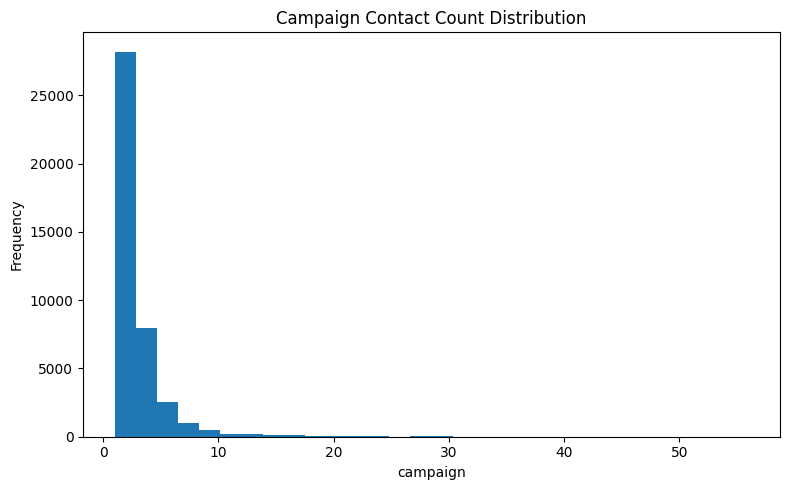

In [8]:
# 3.6 Numerical skewness and compact distribution diagnostics
skewness = df[numerical_columns].skew().sort_values(key=lambda s: s.abs(), ascending=False)
display(skewness.rename("skewness").to_frame())

plt.figure(figsize=(8,5))
plt.hist(df["campaign"], bins=30)
plt.title("Campaign Contact Count Distribution")
plt.xlabel("campaign")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
plt.close()

### Interpretation — outliers and unusual observations

High values in variables such as campaign contact counts can be genuine operational observations. Removing them purely because they look like statistical outliers could delete meaningful customer behaviour. Instead, the notebook uses transformations such as `log1p(campaign)` and `log1p(previous)` and lets tree-based methods model nonlinear effects without arbitrary row deletion.

Columns containing duration: ['duration']


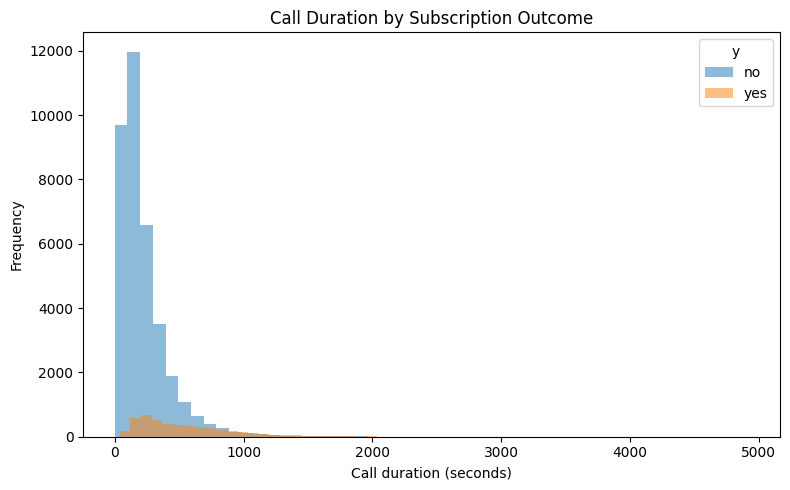

Decision: remove 'duration' from the pre-call model because it is measured during/after the current contact.


In [9]:
# 3.7 Leakage investigation — duration
print("Columns containing duration:", [c for c in df.columns if "duration" in c.lower()])

plt.figure(figsize=(8,5))
for label, subset in df.groupby(TARGET):
    plt.hist(subset["duration"], bins=50, alpha=0.5, label=label)
plt.title("Call Duration by Subscription Outcome")
plt.xlabel("Call duration (seconds)")
plt.ylabel("Frequency")
plt.legend(title=TARGET)
plt.tight_layout()
plt.show()
plt.close()

print("Decision: remove 'duration' from the pre-call model because it is measured during/after the current contact.")

### Why `duration` is treated as leakage

BankReach is intended to score a customer **before** or at the start of prioritization for the current call. `duration` is only known after the current call has taken place, so including it would let the model use information that is unavailable at the intended decision time.

In [10]:
# 3.8 pdays sentinel and previous-contact history
pdays_999 = int((df["pdays"] == 999).sum())
print(f"pdays = 999 count: {pdays_999:,}")
print(f"pdays = 999 percentage: {100*pdays_999/len(df):.2f}%")
print("Most common pdays values:")
display(df["pdays"].value_counts().head(15).to_frame("count"))
print("poutcome distribution:")
display(df["poutcome"].value_counts().to_frame("count"))

pdays = 999 count: 39,673
pdays = 999 percentage: 96.32%
Most common pdays values:


,count
pdays,
999,39673
3,439
6,412
4,118
9,64
2,61
7,60
12,58
10,52


poutcome distribution:


,count
poutcome,
nonexistent,35563
failure,4252
success,1373


### Interpretation — `pdays = 999`

`999` behaves as a sentinel for customers who were not previously contacted or for whom a previous-contact interval is not available. The feature-engineering stage therefore converts `999` to a missing-style distance and adds explicit history indicators instead of treating 999 as a normal elapsed-day measurement.

job: highest observed category rates


,subscription_rate_%
job,
student,31.43
retired,25.23
unemployed,14.20
admin.,12.97
management,11.22
unknown,11.21
technician,10.83
self-employed,10.49


education: highest observed category rates


,subscription_rate_%
education,
illiterate,22.22
unknown,14.50
university.degree,13.72
professional.course,11.35
high.school,10.84
basic.4y,10.25
basic.6y,8.20
basic.9y,7.82


month: highest observed category rates


,subscription_rate_%
month,
mar,50.55
dec,48.90
sep,44.91
oct,43.87
apr,20.48
aug,10.60
jun,10.51
nov,10.14


poutcome: highest observed category rates


,subscription_rate_%
poutcome,
success,65.11
failure,14.23
nonexistent,8.83


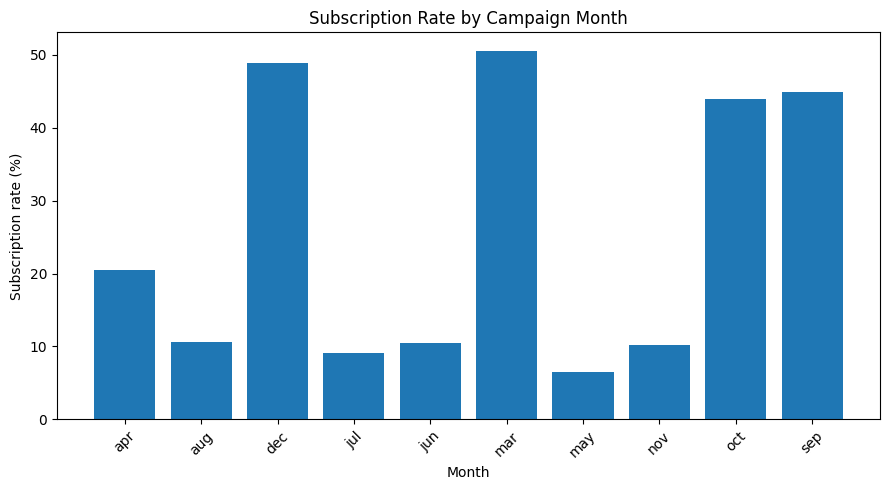

In [11]:
# 3.9 Subscription-rate analysis for selected categorical predictors
def subscription_rate_table(data, column):
    return (data.groupby(column, observed=False)[TARGET]
            .apply(lambda x: (x == "yes").mean() * 100)
            .sort_values(ascending=False))

selected_categorical = ["job", "education", "month", "poutcome"]
for col in selected_categorical:
    rates = subscription_rate_table(df, col)
    summary = rates.rename("subscription_rate_%").round(2)
    print(f"{col}: highest observed category rates")
    display(summary.head(8).to_frame())

rates = subscription_rate_table(df, "month").sort_index()
plt.figure(figsize=(9,5))
plt.bar(rates.index.astype(str), rates.values)
plt.title("Subscription Rate by Campaign Month")
plt.xlabel("Month")
plt.ylabel("Subscription rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.close()

,Feature,Target,Median,Mean
0,age,no,38.000,39.911
1,age,yes,37.000,40.913
2,campaign,no,2.000,2.633
3,campaign,yes,2.000,2.052
4,previous,no,0.000,0.132
5,previous,yes,0.000,0.493
6,euribor3m,no,4.857,3.811
7,euribor3m,yes,1.266,2.123


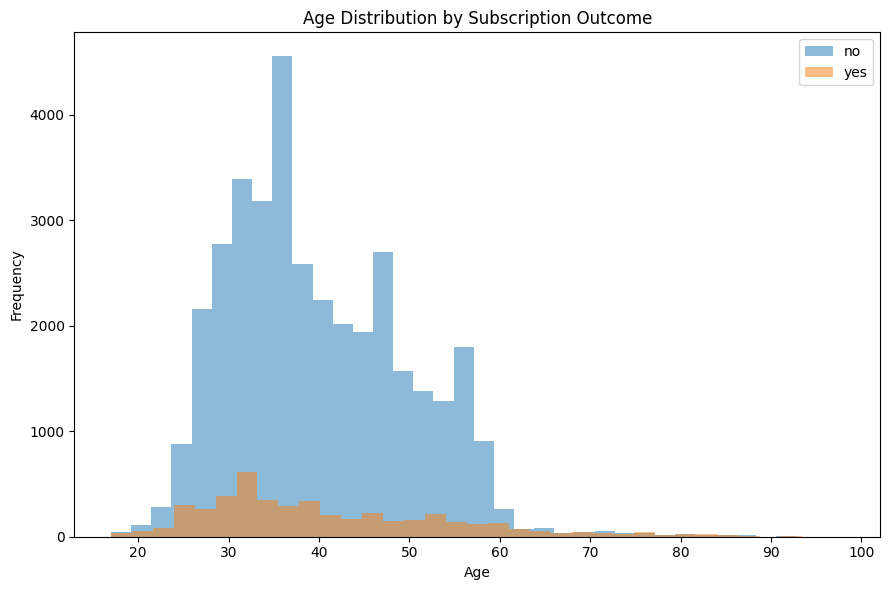

In [12]:
# 3.10 Compact numerical relationship view
selected_numeric = ["age", "campaign", "previous", "euribor3m"]
summary_rows=[]
for col in selected_numeric:
    for label in ["no","yes"]:
        vals=df.loc[df[TARGET]==label,col]
        summary_rows.append({"Feature":col,"Target":label,"Median":vals.median(),"Mean":vals.mean()})
comparison_df=pd.DataFrame(summary_rows)
display(comparison_df.round(3))

plt.figure(figsize=(9,6))
for label in ["no","yes"]:
    plt.hist(df.loc[df[TARGET]==label,"age"], bins=35, alpha=0.5, label=label)
plt.title("Age Distribution by Subscription Outcome")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

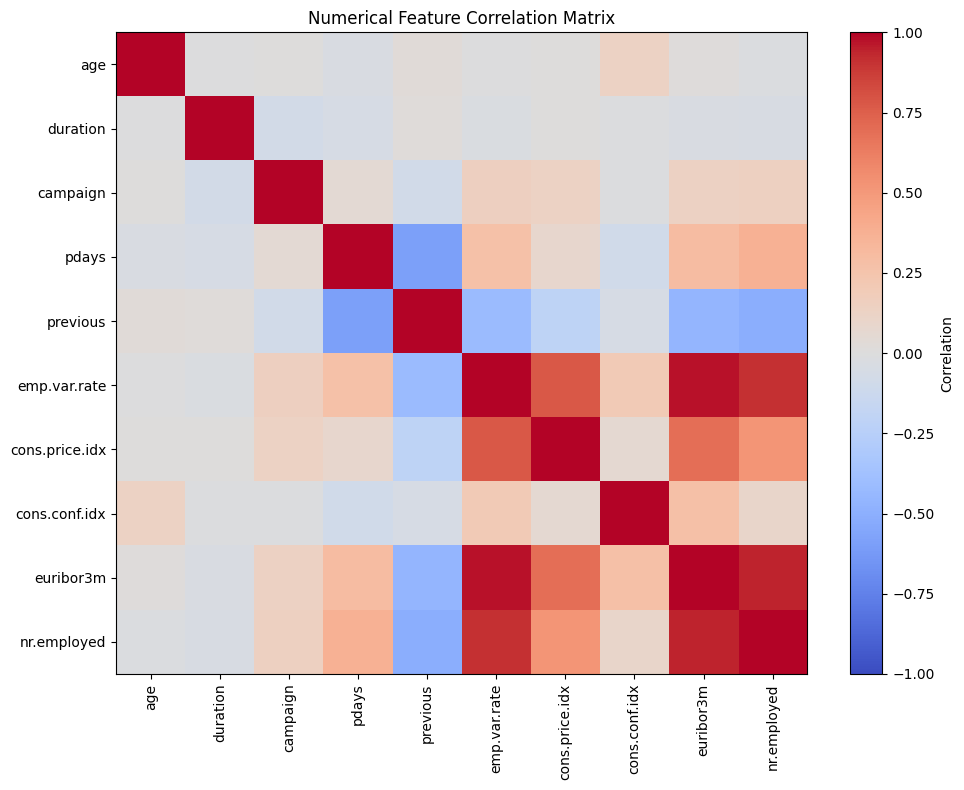

In [13]:
# 3.11 Numerical correlation matrix (predictors only)
corr_cols = [c for c in numerical_columns if c != TARGET]
corr = df[corr_cols].corr()
plt.figure(figsize=(10,8))
plt.imshow(corr, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()
plt.close()

In [14]:
# 3.11A Chronological-order evidence from the supplied full dataset
# The UCI metadata states that bank-additional-full.csv is ordered by date.
# The CSV itself has no year column, so we verify the observable month sequence
# without pretending to reconstruct exact calendar dates.
month_order = {"jan":1,"feb":2,"mar":3,"apr":4,"may":5,"jun":6,
               "jul":7,"aug":8,"sep":9,"oct":10,"nov":11,"dec":12}
month_num_raw = df["month"].map(month_order)
month_backward = month_num_raw.diff() < 0
backward_points = pd.DataFrame({
    "Row index": df.index[month_backward.fillna(False)].tolist(),
    "Previous month": df["month"].shift(1)[month_backward.fillna(False)].tolist(),
    "Current month": df["month"][month_backward.fillna(False)].tolist(),
})

print("UCI-documented order: ordered by date from May 2008 to November 2010")
print("Rows in supplied file:", len(df))
print("Observable backward month transitions:", len(backward_points))
if not backward_points.empty:
    display(backward_points)
print("Interpretation: month labels repeat across years, so repeated months are expected.")
print("Chronological evaluation uses row position as documented by UCI; exact years are not reconstructed.")

UCI-documented order: ordered by date from May 2008 to November 2010
Rows in supplied file: 41188
Observable backward month transitions: 2


,Row index,Previous month,Current month
0,27690,dec,mar
1,39130,dec,mar


Interpretation: month labels repeat across years, so repeated months are expected.
Chronological evaluation uses row position as documented by UCI; exact years are not reconstructed.


## 3.12 Important Stage 3 findings → modelling decisions

| EDA finding | Modelling decision |
|---|---|
| Strong target imbalance | Use PR-AUC as the primary ranking metric and report recall/F1/F2/balanced accuracy |
| `unknown` is an observed category | Keep and one-hot encode it rather than deleting the rows |
| Exact duplicate rows exist | Remove exact duplicates before modelling |
| `duration` is post-call | Exclude it to prevent target leakage |
| `pdays = 999` is a sentinel | Replace it with a missing-style distance representation plus explicit history indicators |
| Campaign counts are right-skewed | Add `log1p(campaign)` and a high-contact flag |
| Previous-contact counts are sparse | Add `log1p(previous)` and contact-history flags |
| Age may have nonlinear effects | Add `age_squared` and `age_group` |
| Month/day-of-week are cyclical | Add numeric cyclical encodings while preserving categorical information |
| UCI documents the full file as date-ordered | Preserve row order and use chronological 70/15/15 holdout splitting plus `TimeSeriesSplit` for model development |
| Later observations have a different target rate | Treat this as a temporal-distribution-shift diagnostic rather than randomly mixing future observations into training |


# ============================================================
# STAGE 4 — DATA PREPROCESSING AND FEATURE ENGINEERING
# ============================================================

### Design principle

Stage 4 defines the transformation logic. The authoritative modelling path is the complete `Pipeline` used later in Stage 6/7. This avoids fitting a preprocessing transformer on the whole dataset and then reusing it inside cross-validation, which could leak fold-validation information into learned statistics or category vocabularies.

In [15]:
# 4.1 Remove exact duplicates and post-contact leakage BEFORE the modelling split.
df_clean = df_original.drop_duplicates().reset_index(drop=True).copy()
df_clean = df_clean.drop(columns=LEAKAGE_FEATURES, errors="ignore")

print("Original rows:", len(df_original))
print("Rows after duplicate removal:", len(df_clean))
print("Removed leakage columns:", LEAKAGE_FEATURES)
print("Clean modelling shape:", df_clean.shape)

Original rows: 41188
Rows after duplicate removal: 41176
Removed leakage columns: ['duration']
Clean modelling shape: (41176, 20)


In [16]:
# 4.2 Chronological 70/15/15 split — final validation strategy
# IMPORTANT: preserve the documented row order. No shuffle and no stratification.
# After duplicate removal, the remaining rows retain their original order.

X_all = df_clean.drop(columns=[TARGET]).copy()
y_all = (df_clean[TARGET] == "yes").astype(int)

n_total = len(X_all)
n_train = int(np.floor(0.70 * n_total))
n_val = int(np.floor(0.15 * n_total))
n_test = n_total - n_train - n_val

X_train_raw = X_all.iloc[:n_train].copy()
y_train_raw = y_all.iloc[:n_train].copy()

X_val_raw = X_all.iloc[n_train:n_train+n_val].copy()
y_val_raw = y_all.iloc[n_train:n_train+n_val].copy()

X_test_raw = X_all.iloc[n_train+n_val:].copy()
y_test_raw = y_all.iloc[n_train+n_val:].copy()

split_summary = pd.DataFrame({
    "Split": ["Train (earliest 70%)", "Validation (next 15%)", "Test (latest 15%)"],
    "Rows": [len(X_train_raw), len(X_val_raw), len(X_test_raw)],
    "Positive Count": [int(y_train_raw.sum()), int(y_val_raw.sum()), int(y_test_raw.sum())],
    "Positive %": [100*y_train_raw.mean(), 100*y_val_raw.mean(), 100*y_test_raw.mean()],
})
display(split_summary.round({"Positive %": 2}))

month_by_split = pd.DataFrame({
    "Train months": X_train_raw["month"].value_counts().to_dict(),
    "Validation months": X_val_raw["month"].value_counts().to_dict(),
    "Test months": X_test_raw["month"].value_counts().to_dict(),
}).fillna(0)
display(month_by_split.astype(int))

print("Split method: chronological / position-based; raw row order preserved.")
print("No shuffling and no stratification were applied.")
print("This design respects the official UCI statement that the full file is ordered by date.")

,Split,Rows,Positive Count,Positive %
0,Train (earliest 70%),28823,1607,5.58
1,Validation (next 15%),6176,657,10.64
2,Test (latest 15%),6177,2375,38.45


,Train months,Validation months,Test months
may,7762,4578,1427
jul,6681,0,488
aug,5173,0,1003
jun,4374,0,944
nov,3615,0,485
apr,859,1598,174
mar,282,0,264
oct,67,0,650
dec,10,0,172
sep,0,0,570


Split method: chronological / position-based; raw row order preserved.
No shuffling and no stratification were applied.
This design respects the official UCI statement that the full file is ordered by date.


### Why chronological splitting is used in the final notebook

The official UCI documentation explicitly states that **`bank-additional-full.csv` is ordered by date from May 2008 to November 2010**. Therefore, the row order is treated as the available time ordering for this historical dataset.

The CSV does **not** contain a year column, so this notebook does not invent exact dates. Repeated values such as `may`, `jun`, or `nov` are expected because multiple years are represented.

The dataset is split without shuffling:

- the earliest 70% are used for model development;
- the next 15% are reserved for validation and operating-threshold selection;
- the latest 15% are held out as the final test set.

This design is intentionally stricter than a random stratified split because it evaluates whether a model trained on earlier campaign periods can generalize to later observations. A consequence is that class proportions can differ substantially between periods; that difference is reported rather than artificially removed.


In [17]:
# 4.3 Leakage-safe feature engineering definition
class BankReachFeatureEngineer(BaseEstimator, TransformerMixin):
    """Feature engineering with the only learned threshold fitted on input X."""

    def fit(self, X, y=None):
        X = X.copy()
        self.campaign_threshold_ = float(X["campaign"].quantile(0.90))
        return self

    def transform(self, X):
        X = X.copy()

        # Previous-contact semantics
        X["previously_contacted"] = (X["poutcome"] != "nonexistent").astype(int)
        X["days_since_previous_contact"] = X["pdays"].replace(999, np.nan)
        X = X.drop(columns=["pdays"], errors="ignore")

        # Previous-campaign information
        X["previous_campaign_contacted"] = (X["previous"] > 0).astype(int)
        X["previous_contact_intensity"] = np.log1p(X["previous"])
        X["previous_success"] = (X["poutcome"] == "success").astype(int)
        X["previous_failure"] = (X["poutcome"] == "failure").astype(int)
        X["no_previous_campaign"] = (X["poutcome"] == "nonexistent").astype(int)

        # Current-campaign intensity
        X["campaign_log"] = np.log1p(X["campaign"])
        X["high_campaign_contact"] = (X["campaign"] >= self.campaign_threshold_).astype(int)

        # Age nonlinearity
        X["age_squared"] = X["age"] ** 2
        X["age_group"] = pd.cut(
            X["age"],
            bins=[0, 25, 35, 45, 55, 65, 100],
            labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"]
        )

        # Financial obligation count
        X["financial_obligation_count"] = (
            (X["default"] == "yes").astype(int)
            + (X["housing"] == "yes").astype(int)
            + (X["loan"] == "yes").astype(int)
        )

        # Cyclical month encoding
        month_order = {"jan":1,"feb":2,"mar":3,"apr":4,"may":5,"jun":6,
                       "jul":7,"aug":8,"sep":9,"oct":10,"nov":11,"dec":12}
        X["month_num"] = X["month"].map(month_order)
        X["month_sin"] = np.sin(2 * np.pi * X["month_num"] / 12)
        X["month_cos"] = np.cos(2 * np.pi * X["month_num"] / 12)

        # Cyclical day-of-week encoding
        day_order = {"mon":0,"tue":1,"wed":2,"thu":3,"fri":4}
        X["day_num"] = X["day_of_week"].map(day_order)
        X["day_sin"] = np.sin(2 * np.pi * X["day_num"] / 7)
        X["day_cos"] = np.cos(2 * np.pi * X["day_num"] / 7)

        # Economic-context interactions
        X["employment_interest_interaction"] = X["emp.var.rate"] * X["euribor3m"]
        X["employment_rate_x_employed"] = X["emp.var.rate"] * X["nr.employed"]

        return X

feature_check = BankReachFeatureEngineer()
X_train_engineered = feature_check.fit_transform(X_train_raw)

print("Raw training columns:", X_train_raw.shape[1])
print("Engineered training columns:", X_train_engineered.shape[1])
print("Learned high-campaign threshold (training only):", round(feature_check.campaign_threshold_, 4))
display(X_train_engineered.head(3))

Raw training columns: 19
Engineered training columns: 38
Learned high-campaign threshold (training only): 5.0


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,previously_contacted,days_since_previous_contact,previous_campaign_contacted,previous_contact_intensity,previous_success,previous_failure,no_previous_campaign,campaign_log,high_campaign_contact,age_squared,age_group,financial_obligation_count,month_num,month_sin,month_cos,day_num,day_sin,day_cos,employment_interest_interaction,employment_rate_x_employed
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,NaN,0,0.0,0,0,1,0.693147,0,3136,56-65,0,5,0.5,-0.866025,0,0.0,1.0,5.3427,5710.1
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,NaN,0,0.0,0,0,1,0.693147,0,3249,56-65,0,5,0.5,-0.866025,0,0.0,1.0,5.3427,5710.1
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,NaN,0,0.0,0,0,1,0.693147,0,1369,36-45,1,5,0.5,-0.866025,0,0.0,1.0,5.3427,5710.1


In [18]:
# 4.4 Define the preprocessing builder once.
def make_preprocessor(numeric_features, categorical_features):
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder)
    ])

    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ], remainder="drop")

numeric_features_model = X_train_engineered.select_dtypes(include=np.number).columns.tolist()
categorical_features_model = X_train_engineered.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric engineered features:", len(numeric_features_model))
print("Categorical engineered features:", len(categorical_features_model))

Numeric engineered features: 27
Categorical engineered features: 11


In [19]:
# 4.5 Training-only preprocessing sanity check — diagnostic, NOT the final modelling input.
sanity_preprocessor = make_preprocessor(numeric_features_model, categorical_features_model)
X_train_sanity = sanity_preprocessor.fit_transform(X_train_engineered)

feature_names = sanity_preprocessor.get_feature_names_out()
print("Training-only transformed matrix:", X_train_sanity.shape)
print("Encoded feature count:", len(feature_names))
print("No validation/test observations were used to fit this diagnostic transformer.")

Training-only transformed matrix: (28823, 86)
Encoded feature count: 86
No validation/test observations were used to fit this diagnostic transformer.


,mutual_information
num__employment_interest_interaction,0.016199
num__cons.conf.idx,0.014578
num__euribor3m,0.014373
num__employment_rate_x_employed,0.013633
num__cons.price.idx,0.013303
num__month_num,0.012924
num__month_cos,0.012092
num__month_sin,0.011828
num__emp.var.rate,0.010288
num__nr.employed,0.009626


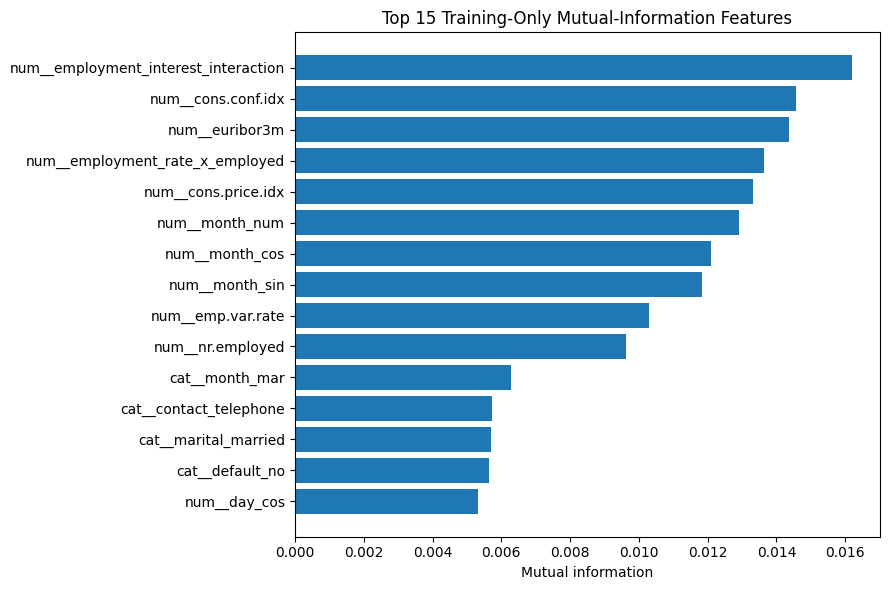

In [20]:
# 4.6 Mutual-information diagnostic on the training partition only
mi_scores = mutual_info_classif(X_train_sanity, y_train_raw, random_state=RANDOM_STATE)
mi_ranking = pd.Series(mi_scores, index=feature_names).sort_values(ascending=False)
display(mi_ranking.head(20).to_frame("mutual_information"))

plt.figure(figsize=(9,6))
top_mi = mi_ranking.head(15).sort_values()
plt.barh(top_mi.index.astype(str), top_mi.values)
plt.xlabel("Mutual information")
plt.title("Top 15 Training-Only Mutual-Information Features")
plt.tight_layout()
plt.show()

In [21]:
# 4.7 Reference class weights from the training partition only
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0,1]),
    y=y_train_raw
)
class_weight_dict = {0: float(class_weights[0]), 1: float(class_weights[1])}
print("Reference class weights:", class_weight_dict)

Reference class weights: {0: 0.5295230746619636, 1: 8.967952706907282}


### Stage 4 preprocessing justification

- **Duplicates:** exact duplicate rows are removed to prevent repeated observations from affecting evaluation disproportionately.
- **Missing values:** pipeline-level imputers are retained for robustness even though the supplied file has zero true NaN cells.
- **Categorical encoding:** one-hot encoding with `handle_unknown="ignore"` converts nominal categories to numerical features and prevents inference-time failures for unseen categories.
- **Numerical scaling:** numerical variables are median-imputed and standardized for consistent use, particularly for Logistic Regression.
- **Outliers:** not deleted mechanically; skewed count features receive logarithmic transformations.
- **Feature engineering:** adds campaign-history flags, nonlinear age representation, cyclical calendar variables and economic interactions.
- **Leakage prevention:** `duration` is removed, and all learned transformation steps are executed inside the model pipeline during cross-validation.
- **Feature selection:** investigated later as an experiment rather than assumed beneficial.

# ============================================================
# STAGE 5 — PROGRESS EVALUATION 1 / INDIVIDUAL VIVA PREPARATION
# ============================================================

Use the following questions to practise explaining the work completed up to preprocessing.

### Viva question bank — Stage 5

**1. What problem are you solving?**  
Predict whether a bank customer will subscribe to a term deposit from pre-call customer and campaign information.

**2. Why is it classification?**  
The target has two outcomes: `yes` and `no`.

**3. Why is class imbalance important?**  
The positive class is much smaller overall, and the positive rate also changes across the chronological periods. Accuracy alone could therefore hide poor detection of subscriptions.

**4. Why did you keep `unknown` categories?**  
They are observed categorical values in the supplied dataset, not necessarily rows that should be deleted. They are retained and encoded as explicit categories.

**5. Why remove duplicates?**  
Exact duplicates are repeated observations and can distort learning and evaluation.

**6. Why remove `duration`?**  
It is only known after the current contact, so it is unavailable at the intended pre-call prediction time. Keeping it would introduce target leakage.

**7. Why transform `pdays`?**  
`999` acts as a sentinel for no previous-contact interval. Treating it as a genuine 999-day distance is misleading, so the model receives a missing-style distance plus history indicators.

**8. Why is the split chronological?**  
The UCI documentation states that the full file is ordered by date from May 2008 to November 2010. Chronological holdout therefore matches the dataset's documented ordering and gives a forward-looking evaluation.

**9. Why do month names repeat?**  
Because the dataset spans multiple years. The notebook does not try to reconstruct the missing year; it relies on UCI's documented row ordering.

**10. Why use a preprocessing `Pipeline`?**  
Any learned preprocessing, such as imputation statistics, scaling, one-hot encoding state, feature-engineering thresholds and feature selection, must be fitted only on the training portion of each fold.


### Individual contribution record — complete before submission

| Item | Your evidence |
|---|---|
| Main technical area completed by me | **[Write your genuine contribution]** |
| Notebook cells / modules developed | **[List the relevant cells/files]** |
| Key preprocessing or modelling decision I can defend | **[Write it]** |
| GitHub commits / screenshots / lab evidence | **[Attach or reference evidence]** |

# ============================================================
# STAGE 6 — MODEL DEVELOPMENT
# ============================================================

## 6.1 Required algorithms

Four suitable algorithms are implemented and compared:

1. **Logistic Regression** — interpretable linear baseline.
2. **Decision Tree** — nonlinear, rule-based model.
3. **Random Forest** — bagged tree ensemble for nonlinear relationships and interactions.
4. **Histogram Gradient Boosting** — boosted tabular model for nonlinear decision boundaries.

## 6.2 Validation strategy

The training partition is evaluated with **5-fold `TimeSeriesSplit`**. This preserves temporal order: every validation fold occurs after its corresponding training window. The separate validation set remains untouched during baseline cross-validation and hyperparameter search. The final test set is untouched until the final evaluation.

## 6.3 Metrics

**Primary ranking metric:** Average Precision (PR-AUC).  
**Supporting metrics:** ROC-AUC, accuracy, balanced accuracy, precision, recall, F1 and F2.

PR-AUC is emphasized because the positive class is uncommon overall and because operational performance depends on the precision/recall trade-off rather than raw accuracy.

## 6.4 Leakage control during validation

Every model is built as a single end-to-end `Pipeline`:

`raw features → feature engineering → preprocessing → classifier`

This means transformations are learned separately inside each fold instead of being fitted once on the complete dataset before cross-validation.

In [22]:
# 6.4 Build the authoritative end-to-end model pipeline

def create_model_pipeline(model):
    return Pipeline([
        ("feature_engineering", BankReachFeatureEngineer()),
        ("preprocessing", make_preprocessor(numeric_features_model, categorical_features_model)),
        ("model", clone(model))
    ])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=30,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=1
    ),
    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=60,
        learning_rate=0.08,
        random_state=RANDOM_STATE
    )
}

cv = TimeSeriesSplit(n_splits=5)

scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
}

print("Validation splitter:", cv)
print("Algorithms:", list(models.keys()))

Validation splitter: TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)
Algorithms: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Histogram Gradient Boosting']


In [23]:
# 6.5 Baseline comparison — 5-fold chronological cross-validation
baseline_rows = []
baseline_fold_details = {}

for name, model in models.items():
    print(f"Running baseline CV: {name}")
    pipeline = create_model_pipeline(model)
    result = cross_validate(
        pipeline,
        X_train_raw,
        y_train_raw,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )
    baseline_fold_details[name] = result
    baseline_rows.append({
        "Model": name,
        "CV PR-AUC": result["test_average_precision"].mean(),
        "CV PR-AUC SD": result["test_average_precision"].std(),
        "CV ROC-AUC": result["test_roc_auc"].mean(),
        "CV Balanced Accuracy": result["test_balanced_accuracy"].mean(),
        "CV Precision": result["test_precision"].mean(),
        "CV Recall": result["test_recall"].mean(),
        "CV F1": result["test_f1"].mean(),
        "CV F2": result["test_f2"].mean(),
    })

baseline_results_df = pd.DataFrame(baseline_rows).sort_values("CV PR-AUC", ascending=False).reset_index(drop=True)
display(baseline_results_df.round(4))

print("Interpretation rule: compare models under the same chronological folds and inspect fold variability, not accuracy alone.")

Running baseline CV: Logistic Regression


Running baseline CV: Decision Tree


Running baseline CV: Random Forest


Running baseline CV: Histogram Gradient Boosting


,Model,CV PR-AUC,CV PR-AUC SD,CV ROC-AUC,CV Balanced Accuracy,CV Precision,CV Recall,CV F1,CV F2
0,Logistic Regression,0.0935,0.0799,0.5463,0.5092,0.0626,0.7793,0.1151,0.2329
1,Histogram Gradient Boosting,0.0706,0.0341,0.5153,0.5000,0.0000,0.0000,0.0000,0.0000
2,Random Forest,0.0639,0.0256,0.4923,0.5013,0.1300,0.0039,0.0076,0.0049
3,Decision Tree,0.0610,0.0220,0.4953,0.4953,0.0539,0.0472,0.0439,0.0445


Interpretation rule: compare models under the same chronological folds and inspect fold variability, not accuracy alone.


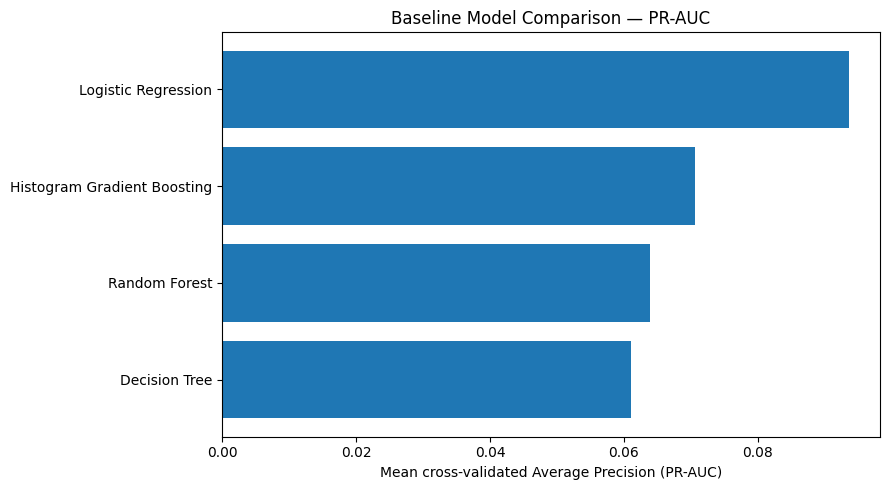

In [24]:
# 6.6 Baseline PR-AUC comparison
plot_df = baseline_results_df.sort_values("CV PR-AUC")
plt.figure(figsize=(9,5))
plt.barh(plot_df["Model"], plot_df["CV PR-AUC"])
plt.xlabel("Mean cross-validated Average Precision (PR-AUC)")
plt.title("Baseline Model Comparison — PR-AUC")
plt.tight_layout()
plt.show()

### 6.7 Why the separate validation period is reserved

The four baseline algorithms are compared quantitatively using the common **5-fold chronological cross-validation** above. The separate chronological validation period is deliberately reserved for the next stage, where the selected tuned candidate is evaluated and its operating threshold is chosen. This avoids using the same holdout period for multiple selection tasks.

### Stage 6 interpretation framework

Do not rely on accuracy alone. For this task, compare **PR-AUC under the same chronological folds**, inspect ROC-AUC and class-sensitive metrics, and consider the standard deviation across folds.

A large difference between training-era and later-era performance is not automatically a coding error: it can indicate **temporal distribution shift**. That distinction is important for the final report and viva.

# ============================================================
# STAGE 7 — MODEL OPTIMIZATION AND FINAL MODEL SELECTION
# ============================================================

Stage 7 demonstrates controlled optimization rather than selecting a model from a single run. It includes hyperparameter search, baseline-vs-tuned comparison, feature-engineering ablation, feature-selection investigation, validation-only threshold selection, final refitting and final test evaluation.

**Computationally bounded search:** all four required Stage 6 algorithms are tuned using a reproducible `RandomizedSearchCV` with **2 trials per algorithm and 3 chronological folds**. Stage 6 retains the fuller 5-fold chronological baseline comparison; Stage 7 optimization comparisons use a common 3-fold chronological development scheme to keep the experiments executable on the available environment.


In [25]:
# 7.1 Hyperparameter search spaces
search_spaces = {
    "Logistic Regression": {
        "model__C": loguniform(0.01, 10.0),
        "model__solver": ["liblinear", "lbfgs"]
    },
    "Decision Tree": {
        "model__max_depth": [3, 5, 8, 12, 16, 24, None],
        "model__min_samples_split": randint(2, 25),
        "model__min_samples_leaf": randint(1, 15),
        "model__max_features": [None, "sqrt", "log2"],
        "model__criterion": ["gini", "entropy"]
    },
    "Random Forest": {
        "model__n_estimators": randint(10, 21),
        "model__max_depth": [None, 8, 12, 16, 24],
        "model__min_samples_split": randint(2, 15),
        "model__min_samples_leaf": randint(1, 8),
        "model__max_features": ["sqrt", "log2", 0.5],
        "model__class_weight": ["balanced", "balanced_subsample"]
    },
    "Histogram Gradient Boosting": {
        "model__learning_rate": loguniform(0.02, 0.2),
        "model__max_iter": randint(30, 51),
        "model__max_leaf_nodes": randint(7, 16),
        "model__max_depth": [None, 3, 5],
        "model__min_samples_leaf": randint(20, 51),
        "model__l2_regularization": loguniform(1e-4, 5.0)
    }
}

# Two trials per algorithm provide a computationally bounded randomized search while preserving
# the required tuning step and chronological validation design.
N_ITER_TUNING = 2
print("RandomizedSearchCV iterations per model:", N_ITER_TUNING)

RandomizedSearchCV iterations per model: 2


In [26]:
# 7.2 Tune all four algorithms using 3-fold chronological CV for the search stage.
# The separate validation and final test sets are not used in hyperparameter search.
tuning_cv = TimeSeriesSplit(n_splits=3)
optimization_cv = TimeSeriesSplit(n_splits=3)

tuned_models = {}
tuning_rows = []

for name, model in models.items():
    print("=" * 78)
    print("TUNING:", name)
    search = RandomizedSearchCV(
        estimator=create_model_pipeline(model),
        param_distributions=search_spaces[name],
        n_iter=N_ITER_TUNING,
        scoring="average_precision",
        cv=tuning_cv,
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbose=0,
        refit=True,
    )
    search.fit(X_train_raw, y_train_raw)
    tuned_models[name] = search
    tuning_rows.append({
        "Model": name,
        "Best Search CV PR-AUC": search.best_score_,
        "Best Parameters": search.best_params_,
    })
    print("Best search CV PR-AUC:", round(search.best_score_, 4))

tuning_results_df = pd.DataFrame(tuning_rows).sort_values("Best Search CV PR-AUC", ascending=False).reset_index(drop=True)
display(tuning_results_df[["Model", "Best Search CV PR-AUC"]].round(4))

print("Search stage uses chronological folds only on the training partition.")

TUNING: Logistic Regression


Best search CV PR-AUC: 0.0996
TUNING: Decision Tree


Best search CV PR-AUC: 0.0657
TUNING: Random Forest


Best search CV PR-AUC: 0.064
TUNING: Histogram Gradient Boosting


Best search CV PR-AUC: 0.0737


,Model,Best Search CV PR-AUC
0,Logistic Regression,0.0996
1,Histogram Gradient Boosting,0.0737
2,Decision Tree,0.0657
3,Random Forest,0.0640


Search stage uses chronological folds only on the training partition.


In [27]:
# 7.3 Baseline vs tuned comparison under the SAME 3-fold chronological optimization CV
# Stage 6 retains the required 5-fold baseline comparison. Here, baseline and tuned
# configurations are re-evaluated under the same lighter 3-fold optimization CV.

optimization_baseline_rows = []
for name, model in models.items():
    baseline_opt = cross_validate(
        create_model_pipeline(model),
        X_train_raw,
        y_train_raw,
        cv=optimization_cv,
        scoring="average_precision",
        n_jobs=1
    )
    optimization_baseline_rows.append({
        "Model": name,
        "Baseline 3-fold optimization CV PR-AUC": baseline_opt["test_score"].mean(),
    })

baseline_compare = pd.DataFrame(optimization_baseline_rows)
tuned_eval_rows = []
for name in models:
    tuned_fixed = clone(tuned_models[name].best_estimator_)
    tuned_eval = cross_validate(
        tuned_fixed,
        X_train_raw,
        y_train_raw,
        cv=optimization_cv,
        scoring="average_precision",
        n_jobs=1
    )
    tuned_eval_rows.append({
        "Model": name,
        "Tuned 3-fold optimization CV PR-AUC": tuned_eval["test_score"].mean(),
        "Tuned 3-fold optimization CV PR-AUC SD": tuned_eval["test_score"].std(),
    })

tuned_eval_df = pd.DataFrame(tuned_eval_rows)
baseline_vs_tuned = baseline_compare.merge(tuned_eval_df, on="Model")
baseline_vs_tuned["Improvement"] = (
    baseline_vs_tuned["Tuned 3-fold optimization CV PR-AUC"] - baseline_vs_tuned["Baseline 3-fold optimization CV PR-AUC"]
)
display(baseline_vs_tuned.sort_values("Tuned 3-fold optimization CV PR-AUC", ascending=False).round(4))


,Model,Baseline 3-fold optimization CV PR-AUC,Tuned 3-fold optimization CV PR-AUC,Tuned 3-fold optimization CV PR-AUC SD,Improvement
0,Logistic Regression,0.0985,0.0996,0.0558,0.0011
3,Histogram Gradient Boosting,0.0694,0.0737,0.0242,0.0043
1,Decision Tree,0.0648,0.0657,0.0162,0.0009
2,Random Forest,0.0642,0.0640,0.0135,-0.0001


## 7.4 Final candidate selection rule

The candidate configuration is first identified from **training-only chronological hyperparameter search** using average precision. The final candidate is then checked under the common 5-fold chronological development CV.

The final test set is not used to select the algorithm, hyperparameters or decision threshold.

In [28]:
# Select the candidate from training-only hyperparameter search.
best_model_name = tuning_results_df.iloc[0]["Model"]
best_search = tuned_models[best_model_name]
best_estimator = best_search.best_estimator_
leading_model = clone(best_estimator.named_steps["model"])

# Re-evaluate the fixed selected configuration under the common 3-fold chronological optimization CV.
selected_cv = cross_validate(
    clone(best_estimator),
    X_train_raw,
    y_train_raw,
    cv=optimization_cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

selected_cv_summary = {
    "PR-AUC": selected_cv["test_average_precision"].mean(),
    "ROC-AUC": selected_cv["test_roc_auc"].mean(),
    "Balanced Accuracy": selected_cv["test_balanced_accuracy"].mean(),
    "F1": selected_cv["test_f1"].mean(),
    "F2": selected_cv["test_f2"].mean(),
}

print("Selected tuned candidate:", best_model_name)
print("Best search CV PR-AUC:", round(best_search.best_score_, 6))
print("Common 3-fold optimization CV summary of selected fixed configuration:")
display(pd.DataFrame([selected_cv_summary], index=[best_model_name]).round(4))
print("Best parameters:")
print(json.dumps(best_search.best_params_, indent=2, default=str))

Selected tuned candidate: Logistic Regression
Best search CV PR-AUC: 0.099617
Common 3-fold optimization CV summary of selected fixed configuration:


,PR-AUC,ROC-AUC,Balanced Accuracy,F1,F2
Logistic Regression,0.0996,0.5547,0.5134,0.1228,0.2437


Best parameters:
{
  "model__C": 0.035506214270707714,
  "model__solver": "lbfgs"
}


## 7.5 Feature-engineering ablation

The engineered pipeline is compared with a minimal representation using the **same leading algorithm and the same 3-fold chronological optimization CV**. This tests whether the engineered variables add reproducible predictive signal rather than assuming that more features are always useful.

In [29]:
class BankReachMinimalFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X.copy()

def create_minimal_pipeline(model):
    minimal_sample = X_train_raw.copy()
    nums = minimal_sample.select_dtypes(include=np.number).columns.tolist()
    cats = minimal_sample.select_dtypes(include=["object", "category"]).columns.tolist()
    return Pipeline([
        ("features", BankReachMinimalFeatures()),
        ("preprocessing", make_preprocessor(nums, cats)),
        ("model", clone(model))
    ])

minimal_pipeline = create_minimal_pipeline(leading_model)
engineered_pipeline = clone(best_estimator)

minimal_cv = cross_validate(
    minimal_pipeline, X_train_raw, y_train_raw,
    cv=optimization_cv, scoring="average_precision", n_jobs=1
)
engineered_cv = cross_validate(
    engineered_pipeline, X_train_raw, y_train_raw,
    cv=optimization_cv, scoring="average_precision", n_jobs=1
)

feature_ablation_df = pd.DataFrame({
    "Feature Set": ["Minimal", "Engineered (selected tuned model)"],
    "Mean 3-fold optimization CV PR-AUC": [minimal_cv["test_score"].mean(), engineered_cv["test_score"].mean()],
    "SD 3-fold optimization CV PR-AUC": [minimal_cv["test_score"].std(), engineered_cv["test_score"].std()],
})
display(feature_ablation_df.round(4))

,Feature Set,Mean 3-fold optimization CV PR-AUC,SD 3-fold optimization CV PR-AUC
0,Minimal,0.0919,0.0473
1,Engineered (selected tuned model),0.0996,0.0558


## 7.6 Feature-selection experiment

Mutual-information selection is fitted **inside** the cross-validation pipeline. The 80th-percentile selection is compared with the **same fixed tuned model without feature selection**, evaluated under the same 3-fold chronological optimization CV.

In [30]:
selection_pipeline = Pipeline([
    ("feature_engineering", BankReachFeatureEngineer()),
    ("preprocessing", make_preprocessor(numeric_features_model, categorical_features_model)),
    ("feature_selection", SelectPercentile(score_func=mutual_info_classif, percentile=80)),
    ("model", clone(leading_model))
])

selection_cv_result = cross_validate(
    selection_pipeline,
    X_train_raw,
    y_train_raw,
    cv=optimization_cv,
    scoring="average_precision",
    n_jobs=1
)

tuned_full_cv_result = cross_validate(
    clone(best_estimator),
    X_train_raw,
    y_train_raw,
    cv=optimization_cv,
    scoring="average_precision",
    n_jobs=1
)

feature_selection_df = pd.DataFrame({
    "Approach": ["Selected tuned full feature set", "MI selection (80%)"],
    "Mean 3-fold optimization CV PR-AUC": [tuned_full_cv_result["test_score"].mean(), selection_cv_result["test_score"].mean()],
    "SD 3-fold optimization CV PR-AUC": [tuned_full_cv_result["test_score"].std(), selection_cv_result["test_score"].std()]
})
display(feature_selection_df.round(4))

,Approach,Mean 3-fold optimization CV PR-AUC,SD 3-fold optimization CV PR-AUC
0,Selected tuned full feature set,0.0996,0.0558
1,MI selection (80%),0.0971,0.0528


### Feature-selection decision rule

Feature selection is adopted only when it produces a clear and reproducible improvement under the same validation scheme. Otherwise, the tuned full-feature pipeline remains the reference because discarding information without evidence is not justified.

## 7.7 Validation-only operating-threshold selection

The classifier's ranking ability and its binary operating threshold are separate choices. The tuned candidate is fitted on the **training partition only**, then candidate thresholds are evaluated on the **later validation partition**.

Because BankReach is recall-oriented, **F2** is used for threshold selection. The final test set is not inspected during this step.

In [31]:
# Fit the selected tuned configuration on the training partition only.
best_pipeline = clone(best_estimator)
best_pipeline.fit(X_train_raw, y_train_raw)
val_probability = best_pipeline.predict_proba(X_val_raw)[:,1]

thresholds = np.arange(0.05, 0.81, 0.01)
threshold_rows = []
for threshold in thresholds:
    pred = (val_probability >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_raw, pred, zero_division=0),
        "Recall": recall_score(y_val_raw, pred, zero_division=0),
        "F1": f1_score(y_val_raw, pred, zero_division=0),
        "F2": fbeta_score(y_val_raw, pred, beta=2, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_val_raw, pred),
    })
threshold_df = pd.DataFrame(threshold_rows)

best_threshold_row = threshold_df.sort_values(
    ["F2", "Recall", "Precision"], ascending=[False, False, False]
).iloc[0]
decision_threshold = float(best_threshold_row["Threshold"])

print("Selected validation threshold:", decision_threshold)
display(threshold_df.sort_values("F2", ascending=False).head(12).round(4))

Selected validation threshold: 0.7000000000000002


,Threshold,Precision,Recall,F1,F2,Balanced Accuracy
65,0.70,0.1205,0.7976,0.2094,0.3756,0.5524
62,0.67,0.1155,0.8554,0.2035,0.3749,0.5377
63,0.68,0.1169,0.8341,0.2051,0.3746,0.5421
28,0.33,0.1064,1.0000,0.1923,0.3732,0.5001
64,0.69,0.1181,0.8113,0.2061,0.3731,0.5450
4,0.09,0.1064,1.0000,0.1923,0.3731,0.5000
6,0.11,0.1064,1.0000,0.1923,0.3731,0.5000
5,0.10,0.1064,1.0000,0.1923,0.3731,0.5000
0,0.05,0.1064,1.0000,0.1923,0.3731,0.5000
1,0.06,0.1064,1.0000,0.1923,0.3731,0.5000


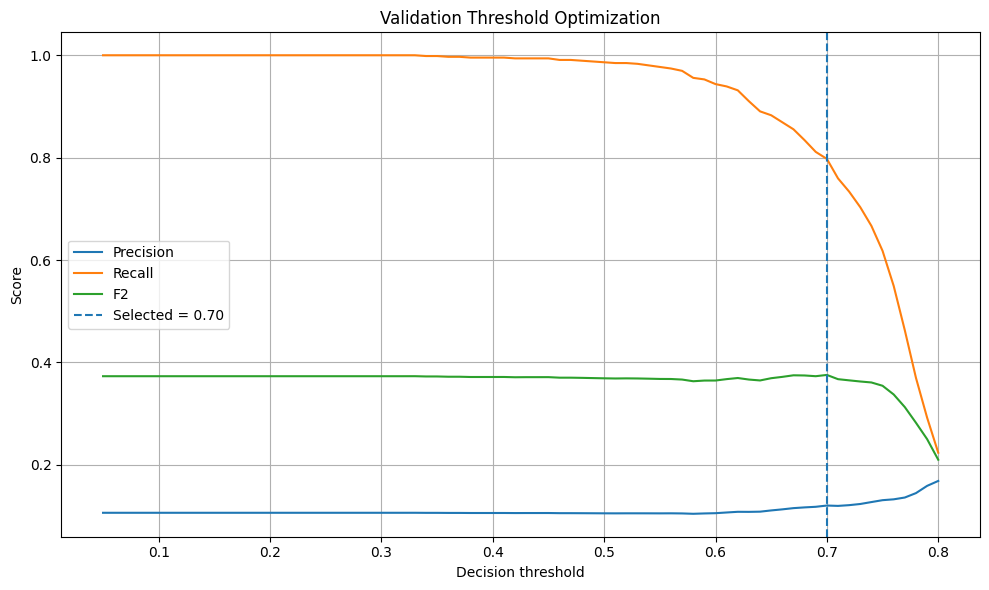

In [32]:
# 7.8 Visualize threshold trade-offs
plt.figure(figsize=(10,6))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F2"], label="F2")
plt.axvline(decision_threshold, linestyle="--", label=f"Selected = {decision_threshold:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Validation Threshold Optimization")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [33]:
# 7.9 Validation metrics for the selected threshold
val_prediction = (val_probability >= decision_threshold).astype(int)
final_validation_metrics = {
    "PR-AUC": average_precision_score(y_val_raw, val_probability),
    "ROC-AUC": roc_auc_score(y_val_raw, val_probability),
    "Accuracy": accuracy_score(y_val_raw, val_prediction),
    "Balanced Accuracy": balanced_accuracy_score(y_val_raw, val_prediction),
    "Precision": precision_score(y_val_raw, val_prediction, zero_division=0),
    "Recall": recall_score(y_val_raw, val_prediction, zero_division=0),
    "F1": f1_score(y_val_raw, val_prediction, zero_division=0),
    "F2": fbeta_score(y_val_raw, val_prediction, beta=2, zero_division=0),
}
display(pd.DataFrame([final_validation_metrics], index=["Validation"]).T.round(4))
print(classification_report(y_val_raw, val_prediction, target_names=["No Subscription", "Subscription"], zero_division=0))

,Validation
PR-AUC,0.1584
ROC-AUC,0.5854
Accuracy,0.3595
Balanced Accuracy,0.5524
Precision,0.1205
Recall,0.7976
F1,0.2094
F2,0.3756


                 precision    recall  f1-score   support

No Subscription       0.93      0.31      0.46      5519
   Subscription       0.12      0.80      0.21       657

       accuracy                           0.36      6176
      macro avg       0.52      0.55      0.34      6176
   weighted avg       0.84      0.36      0.43      6176



In [34]:
# 7.10 Final refit on the combined non-test data
X_development = pd.concat([X_train_raw, X_val_raw], axis=0)
y_development = pd.concat([y_train_raw, y_val_raw], axis=0)

final_pipeline = clone(best_estimator)
final_pipeline.fit(X_development, y_development)

print("Final pipeline fitted on:", X_development.shape)
print("Final test set held out:", X_test_raw.shape)

Final pipeline fitted on: (34999, 19)
Final test set held out: (6177, 19)


In [35]:
# 7.11 Final test evaluation — performed once after model/threshold are fixed
test_probability = final_pipeline.predict_proba(X_test_raw)[:,1]
test_prediction = (test_probability >= decision_threshold).astype(int)

final_test_metrics = {
    "PR-AUC": average_precision_score(y_test_raw, test_probability),
    "ROC-AUC": roc_auc_score(y_test_raw, test_probability),
    "Accuracy": accuracy_score(y_test_raw, test_prediction),
    "Balanced Accuracy": balanced_accuracy_score(y_test_raw, test_prediction),
    "Precision": precision_score(y_test_raw, test_prediction, zero_division=0),
    "Recall": recall_score(y_test_raw, test_prediction, zero_division=0),
    "F1": f1_score(y_test_raw, test_prediction, zero_division=0),
    "F2": fbeta_score(y_test_raw, test_prediction, beta=2, zero_division=0),
}

display(pd.DataFrame([final_test_metrics], index=["Final Test"]).T.round(4))
print(classification_report(y_test_raw, test_prediction, target_names=["No Subscription", "Subscription"], zero_division=0))

,Final Test
PR-AUC,0.5753
ROC-AUC,0.6917
Accuracy,0.6123
Balanced Accuracy,0.6332
Precision,0.4971
Recall,0.7238
F1,0.5894
F2,0.6633


                 precision    recall  f1-score   support

No Subscription       0.76      0.54      0.63      3802
   Subscription       0.50      0.72      0.59      2375

       accuracy                           0.61      6177
      macro avg       0.63      0.63      0.61      6177
   weighted avg       0.66      0.61      0.62      6177



In [36]:
# 7.12 Validation vs final-test generalization
metrics_order = ["PR-AUC", "ROC-AUC", "Accuracy", "Balanced Accuracy", "Precision", "Recall", "F1", "F2"]
generalization_df = pd.DataFrame({
    "Metric": metrics_order,
    "Validation": [final_validation_metrics[m] for m in metrics_order],
    "Final Test": [final_test_metrics[m] for m in metrics_order]
})
display(generalization_df.round(4))

,Metric,Validation,Final Test
0,PR-AUC,0.1584,0.5753
1,ROC-AUC,0.5854,0.6917
2,Accuracy,0.3595,0.6123
3,Balanced Accuracy,0.5524,0.6332
4,Precision,0.1205,0.4971
5,Recall,0.7976,0.7238
6,F1,0.2094,0.5894
7,F2,0.3756,0.6633


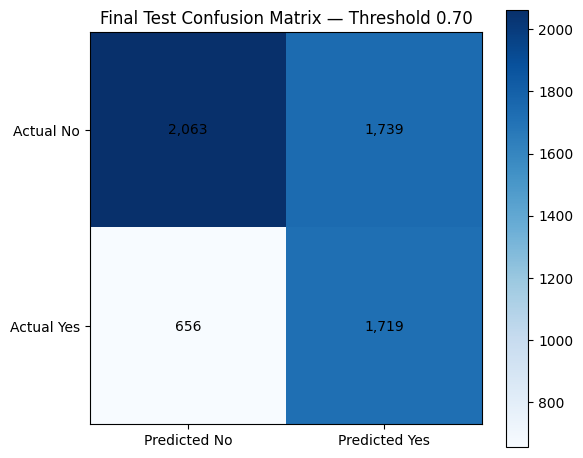

In [37]:
# 7.13 Final confusion matrix
cm_test = confusion_matrix(y_test_raw, test_prediction)
plt.figure(figsize=(6,5))
plt.imshow(cm_test, cmap="Blues")
plt.colorbar()
plt.xticks([0,1], ["Predicted No", "Predicted Yes"])
plt.yticks([0,1], ["Actual No", "Actual Yes"])
plt.title(f"Final Test Confusion Matrix — Threshold {decision_threshold:.2f}")
for (i,j),v in np.ndenumerate(cm_test):
    plt.text(j, i, f"{v:,}", ha="center", va="center")
plt.tight_layout()
plt.show()

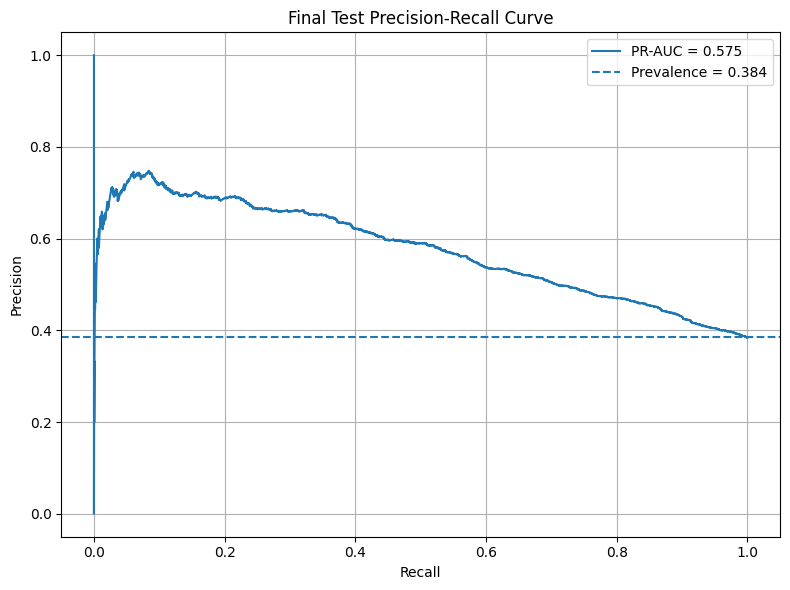

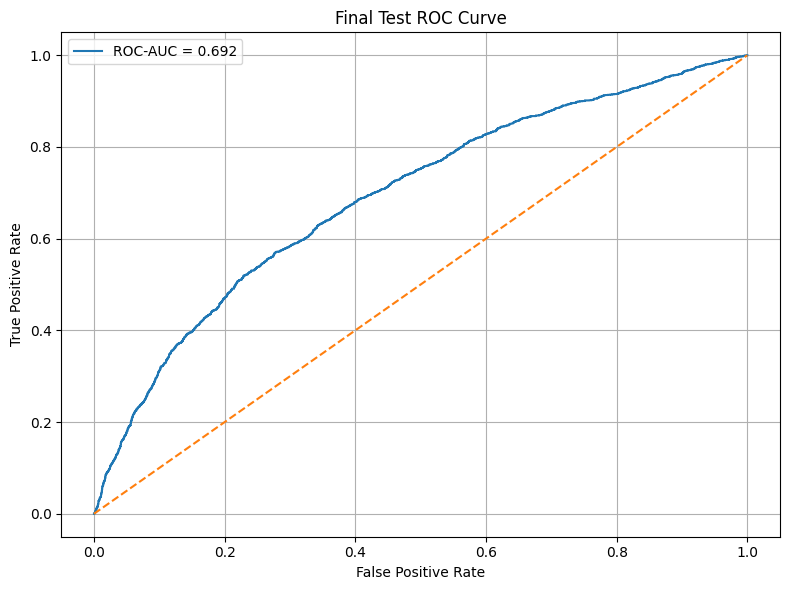

In [38]:
# 7.14 Final PR and ROC curves
precision, recall, _ = precision_recall_curve(y_test_raw, test_probability)
ap = average_precision_score(y_test_raw, test_probability)
plt.figure(figsize=(8,6))
plt.plot(recall, precision, label=f"PR-AUC = {ap:.3f}")
plt.axhline(y_test_raw.mean(), linestyle="--", label=f"Prevalence = {y_test_raw.mean():.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Test Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
plt.close()

fpr, tpr, _ = roc_curve(y_test_raw, test_probability)
auc = roc_auc_score(y_test_raw, test_probability)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Test ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 7.15 Model interpretation — permutation importance

Permutation importance is calculated on the validation data to understand which **original input variables** contribute most to the selected pipeline's PR-AUC. The analysis is descriptive, not causal: a high importance does not prove that the feature causes subscription.

,Feature,Importance,Std
13,poutcome,0.02889,0.00089
0,age,0.01193,0.00106
17,euribor3m,0.00760,0.00053
16,cons.conf.idx,0.00661,0.00056
15,cons.price.idx,0.00348,0.00041
12,previous,0.00333,0.00084
3,education,0.00261,0.00081
4,default,0.00229,0.00060
7,contact,0.00179,0.00102
2,marital,0.00156,0.00035


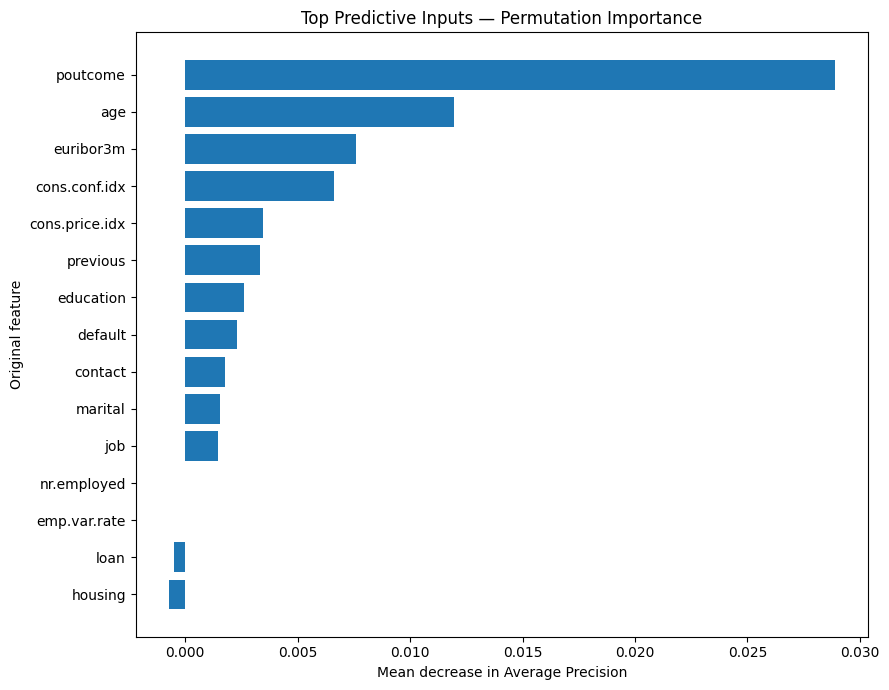

In [39]:
permutation_result = permutation_importance(
    best_pipeline,
    X_val_raw,
    y_val_raw,
    scoring="average_precision",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": X_val_raw.columns,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std,
}).sort_values("Importance", ascending=False)

display(importance_df.head(20).round(5))

plot_features = importance_df.head(15).sort_values("Importance")
plt.figure(figsize=(9,7))
plt.barh(plot_features["Feature"], plot_features["Importance"])
plt.xlabel("Mean decrease in Average Precision")
plt.ylabel("Original feature")
plt.title("Top Predictive Inputs — Permutation Importance")
plt.tight_layout()
plt.show()

## 7.16 Subgroup diagnostics

These checks are descriptive model-quality diagnostics. They do not make a legal or fairness determination. Small groups are suppressed to avoid over-interpreting unstable rates.

In [40]:
test_diagnostic = X_test_raw.copy()
test_diagnostic["actual"] = y_test_raw.to_numpy()
test_diagnostic["probability"] = test_probability
test_diagnostic["prediction"] = test_prediction

test_diagnostic["age_group"] = pd.cut(
    test_diagnostic["age"],
    bins=[0,25,35,45,55,65,100],
    labels=["17-25","26-35","36-45","46-55","56-65","66+"]
)

def subgroup_metrics(data, group_col, min_n=30):
    rows=[]
    for group, part in data.groupby(group_col, dropna=False, observed=False):
        if len(part) < min_n:
            continue
        rows.append({
            group_col: str(group),
            "N": len(part),
            "Actual Positive Rate": part["actual"].mean(),
            "Precision": precision_score(part["actual"], part["prediction"], zero_division=0),
            "Recall": recall_score(part["actual"], part["prediction"], zero_division=0),
            "F1": f1_score(part["actual"], part["prediction"], zero_division=0),
        })
    return pd.DataFrame(rows)

for col in ["age_group", "job", "education", "marital"]:
    print(f"\nSubgroup diagnostics for: {col}")
    display(subgroup_metrics(test_diagnostic, col).round(4))


Subgroup diagnostics for: age_group


,age_group,N,Actual Positive Rate,Precision,Recall,F1
0,17-25,589,0.4058,0.5080,0.7950,0.6199
1,26-35,2234,0.3671,0.4700,0.7171,0.5678
2,36-45,1278,0.3545,0.5519,0.6689,0.6048
3,46-55,890,0.3809,0.5263,0.5900,0.5563
4,56-65,666,0.4099,0.4700,0.7473,0.5771
5,66+,520,0.4827,0.4979,0.9323,0.6491



Subgroup diagnostics for: job


,job,N,Actual Positive Rate,Precision,Recall,F1
0,admin.,1952,0.3904,0.5215,0.7008,0.5980
1,blue-collar,546,0.2821,0.4673,0.6039,0.5269
2,entrepreneur,125,0.3200,0.3846,0.5000,0.4348
3,housemaid,153,0.4183,0.5190,0.6406,0.5734
4,management,428,0.3785,0.4979,0.7160,0.5873
5,retired,712,0.4494,0.4795,0.9156,0.6294
6,self-employed,203,0.3153,0.4175,0.6719,0.5150
7,services,372,0.3226,0.4695,0.6417,0.5423
8,student,479,0.4405,0.4920,0.8720,0.6291
9,technician,903,0.3965,0.5174,0.6648,0.5819



Subgroup diagnostics for: education


,education,N,Actual Positive Rate,Precision,Recall,F1
0,basic.4y,533,0.4409,0.5186,0.7702,0.6199
1,basic.6y,148,0.3649,0.4810,0.7037,0.5714
2,basic.9y,480,0.3042,0.4318,0.6507,0.5191
3,high.school,1419,0.3658,0.4979,0.6994,0.5817
4,professional.course,791,0.4020,0.5195,0.7107,0.6003
5,university.degree,2430,0.3856,0.4957,0.7364,0.5925
6,unknown,372,0.4409,0.4960,0.7622,0.6010



Subgroup diagnostics for: marital


,marital,N,Actual Positive Rate,Precision,Recall,F1
0,divorced,623,0.3756,0.5106,0.7179,0.5968
1,married,3170,0.3924,0.5100,0.6969,0.5890
2,single,2372,0.3756,0.4781,0.7609,0.5873


## 7.17 Practical error analysis

The error analysis identifies false negatives and false positives on the final test set. Because the threshold was selected with F2, the operating point deliberately gives more importance to detecting positives, but errors remain inevitable and should be monitored after deployment.

In [41]:
error_analysis = X_test_raw.copy()
error_analysis["actual"] = y_test_raw.to_numpy()
error_analysis["probability"] = test_probability
error_analysis["prediction"] = test_prediction
error_analysis["error_type"] = np.select(
    [
        (error_analysis["actual"] == 1) & (error_analysis["prediction"] == 0),
        (error_analysis["actual"] == 0) & (error_analysis["prediction"] == 1),
    ],
    ["False Negative", "False Positive"],
    default="Correct"
)

print("False negatives:", int((error_analysis["error_type"] == "False Negative").sum()))
print("False positives:", int((error_analysis["error_type"] == "False Positive").sum()))

print("Highest-confidence false negatives")
display(error_analysis[error_analysis["error_type"] == "False Negative"].sort_values("probability", ascending=False).head(10))

print("Highest-confidence false positives")
display(error_analysis[error_analysis["error_type"] == "False Positive"].sort_values("probability", ascending=False).head(10))

False negatives: 656
False positives: 1739
Highest-confidence false negatives


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,actual,probability,prediction,error_type
38099,39,services,married,high.school,no,no,no,cellular,sep,tue,1,999,0,nonexistent,-3.4,92.379,-29.8,0.755,5017.5,1,0.699795,0,False Negative
36246,31,services,married,basic.9y,no,no,no,cellular,jun,mon,1,999,0,nonexistent,-2.9,92.963,-40.8,1.266,5076.2,1,0.699501,0,False Negative
39841,39,technician,married,university.degree,no,yes,no,cellular,jun,mon,2,999,0,nonexistent,-1.7,94.055,-39.8,0.720,4991.6,1,0.699321,0,False Negative
36361,41,technician,married,professional.course,no,no,no,cellular,jun,tue,2,999,0,nonexistent,-2.9,92.963,-40.8,1.262,5076.2,1,0.699183,0,False Negative
37384,26,student,single,basic.9y,no,no,no,telephone,aug,wed,1,999,0,nonexistent,-2.9,92.201,-31.4,0.879,5076.2,1,0.698865,0,False Negative
36964,32,self-employed,single,university.degree,no,no,no,cellular,jul,thu,2,999,0,nonexistent,-2.9,92.469,-33.6,1.072,5076.2,1,0.698638,0,False Negative
36323,43,blue-collar,married,basic.9y,no,yes,no,cellular,jun,tue,1,999,0,nonexistent,-2.9,92.963,-40.8,1.262,5076.2,1,0.698533,0,False Negative
39957,38,technician,single,university.degree,no,yes,no,cellular,jun,mon,6,999,0,nonexistent,-1.7,94.055,-39.8,0.754,4991.6,1,0.698445,0,False Negative
36227,36,technician,single,university.degree,no,yes,no,cellular,jun,mon,1,999,0,nonexistent,-2.9,92.963,-40.8,1.266,5076.2,1,0.697164,0,False Negative
36928,33,housemaid,married,university.degree,no,no,no,cellular,jun,tue,1,999,0,nonexistent,-2.9,92.963,-40.8,1.099,5076.2,1,0.696840,0,False Negative


Highest-confidence false positives


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,actual,probability,prediction,error_type
40938,81,retired,divorced,basic.4y,no,yes,no,cellular,oct,thu,2,3,2,success,-1.1,94.601,-49.5,0.987,4963.6,0,0.997950,1,False Positive
40954,74,retired,married,university.degree,no,yes,no,cellular,oct,fri,2,3,2,success,-1.1,94.601,-49.5,0.993,4963.6,0,0.997758,1,False Positive
40974,84,retired,divorced,basic.4y,unknown,yes,yes,cellular,oct,mon,4,3,1,success,-1.1,94.601,-49.5,1.000,4963.6,0,0.997190,1,False Positive
40971,74,retired,divorced,basic.4y,no,yes,no,cellular,oct,mon,3,3,2,success,-1.1,94.601,-49.5,1.000,4963.6,0,0.996732,1,False Positive
41041,23,student,single,high.school,no,no,no,cellular,oct,wed,1,3,1,success,-1.1,94.601,-49.5,1.043,4963.6,0,0.996302,1,False Positive
41019,25,student,single,high.school,no,yes,no,cellular,oct,mon,1,6,4,success,-1.1,94.601,-49.5,1.032,4963.6,0,0.996028,1,False Positive
40874,70,retired,married,basic.4y,unknown,no,no,cellular,oct,thu,1,14,3,failure,-1.1,94.601,-49.5,0.965,4963.6,0,0.995963,1,False Positive
41000,65,retired,married,high.school,no,yes,no,cellular,oct,thu,5,3,1,success,-1.1,94.601,-49.5,1.025,4963.6,0,0.995861,1,False Positive
40881,27,student,single,unknown,no,yes,no,cellular,oct,fri,1,20,4,failure,-1.1,94.601,-49.5,0.972,4963.6,0,0.995254,1,False Positive
40946,63,admin.,married,university.degree,no,yes,no,cellular,oct,thu,2,6,1,success,-1.1,94.601,-49.5,0.987,4963.6,0,0.994952,1,False Positive


## 7.18 Limitations and future improvements

1. The CSV does not expose a year column, so the notebook relies on UCI's documented date ordering rather than reconstructing exact row-level dates.
2. Chronological class proportions differ materially across periods; this is treated as temporal distribution shift and should be monitored in a production setting.
3. The dataset is historical and may not represent a current bank customer population.
4. The prediction is decision support; it should not be the sole basis for customer treatment.
5. Probability calibration could be studied separately before operational deployment.
6. Drift monitoring and periodic retraining would be required in a real deployment setting.
7. Fairness monitoring should be expanded according to the actual regulatory and organizational context.


In [42]:
# 7.19 Export the final deployment artifact and metadata
MODEL_ARTIFACT_PATH = "bankreach_final_model.joblib"
METADATA_PATH = "bankreach_model_metadata.json"

model_artifact = {
    "model": final_pipeline,
    "decision_threshold": float(decision_threshold),
    "model_name": best_model_name,
    "target": TARGET,
    "primary_metric": "PR-AUC / Average Precision",
    "threshold_metric": "F2",
    "random_state": RANDOM_STATE,
    "input_columns": X_development.columns.tolist(),
    "excluded_leakage_features": LEAKAGE_FEATURES,
    "rows_after_deduplication": int(len(df_clean)),
    "validation_strategy": "Chronological 70/15/15 split; TimeSeriesSplit for development CV and hyperparameter search",
    "chronology_source": "UCI Machine Learning Repository — Bank Marketing, Dataset ID 222",
}
joblib.dump(model_artifact, MODEL_ARTIFACT_PATH)

metadata = {
    "project": "BankReach — Term-Deposit Subscription Prediction",
    "model_name": best_model_name,
    "decision_threshold": float(decision_threshold),
    "primary_metric": "PR-AUC / Average Precision",
    "threshold_metric": "F2",
    "best_parameters": best_search.best_params_,
    "validation_metrics": {k: float(v) for k,v in final_validation_metrics.items()},
    "test_metrics": {k: float(v) for k,v in final_test_metrics.items()},
    "random_state": RANDOM_STATE,
    "input_columns": X_development.columns.tolist(),
    "excluded_leakage_features": LEAKAGE_FEATURES,
    "rows_after_deduplication": int(len(df_clean)),
    "validation_strategy": "Chronological 70/15/15 split; TimeSeriesSplit for development CV and hyperparameter search",
}
with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, default=str)

print("Saved:", MODEL_ARTIFACT_PATH)
print("Saved:", METADATA_PATH)

Saved: bankreach_final_model.joblib
Saved: bankreach_model_metadata.json


In [43]:
# 7.20 Reload verification
loaded_artifact = joblib.load(MODEL_ARTIFACT_PATH)
print("Loaded model:", loaded_artifact["model_name"])
print("Loaded threshold:", loaded_artifact["decision_threshold"])
print("Loaded input column count:", len(loaded_artifact["input_columns"]))
print("Artifact reload verification: SUCCESS")

Loaded model: Logistic Regression
Loaded threshold: 0.7000000000000002
Loaded input column count: 19
Artifact reload verification: SUCCESS


In [44]:
# 7.21 Final report-ready result summary
summary_rows = [
    ["Dataset rows after duplicate removal", len(df_clean)],
    ["Training rows", len(X_train_raw)],
    ["Validation rows", len(X_val_raw)],
    ["Test rows", len(X_test_raw)],
    ["Leading tuned model", best_model_name],
    ["Best tuning CV PR-AUC", float(best_search.best_score_)],
    ["Validation decision threshold", float(decision_threshold)],
    ["Final test PR-AUC", float(final_test_metrics["PR-AUC"])],
    ["Final test ROC-AUC", float(final_test_metrics["ROC-AUC"])],
    ["Final test balanced accuracy", float(final_test_metrics["Balanced Accuracy"])],
    ["Final test precision", float(final_test_metrics["Precision"])],
    ["Final test recall", float(final_test_metrics["Recall"])],
    ["Final test F1", float(final_test_metrics["F1"])],
    ["Final test F2", float(final_test_metrics["F2"])],
]
summary_df = pd.DataFrame(summary_rows, columns=["Item", "Result"])
display(summary_df)

,Item,Result
0,Dataset rows after duplicate removal,41176
1,Training rows,28823
2,Validation rows,6176
3,Test rows,6177
4,Leading tuned model,Logistic Regression
5,Best tuning CV PR-AUC,0.099617
6,Validation decision threshold,0.7
7,Final test PR-AUC,0.575311
8,Final test ROC-AUC,0.691687
9,Final test balanced accuracy,0.633199


### How to discuss the results in the report

Use the **actual printed values** generated above. Your explanation should cover:

- which algorithm had the strongest cross-validated PR-AUC;
- whether tuning improved the baseline result;
- whether engineered features improved or reduced CV PR-AUC in the ablation;
- whether feature selection improved or reduced performance;
- how the validation-selected threshold changed precision and recall;
- whether validation and final-test performance are reasonably aligned;
- the main practical error types;
- which original inputs were important under permutation analysis; and
- why the final test result is credible: the test partition was not used for model comparison, hyperparameter tuning or threshold selection.

### High-priority viva questions

**1. Why did you choose four different algorithms?**  
They represent different modelling assumptions: linear, single-tree nonlinear, bagged ensemble and boosted ensemble.

**2. Why PR-AUC as the primary metric?**  
The subscription class is uncommon overall, so PR-AUC provides a focused view of precision/recall performance for the positive class.

**3. Why use chronological splitting instead of a random stratified split?**  
The official UCI documentation says the full file is ordered by date from May 2008 to November 2010. A chronological split therefore evaluates forward generalization to later observations.

**4. Why are repeated months not a problem?**  
The dataset covers multiple years. The CSV lacks the year field, so exact years are not reconstructed; chronology is taken from the source documentation.

**5. Why use `TimeSeriesSplit`?**  
Each fold trains on earlier rows and validates on later rows, reducing the risk of training on future observations relative to a fold's validation window.

**6. Why not use the final test set during tuning?**  
Using the test set for tuning would bias the final performance estimate and turn the test set into another selection resource.

**7. Why use RandomizedSearchCV?**  
It explores a defined hyperparameter space with a controlled number of trials, giving a reproducible optimization strategy without exhaustive enumeration.

**8. Why have both tuning CV and a separate validation set?**  
Tuning CV selects hyperparameters using the training partition only. The separate validation period is then used for the operating threshold. This keeps threshold selection separate from hyperparameter search.

**9. Why select a threshold instead of always using 0.50?**  
The threshold controls the precision/recall trade-off. F2 is used because the project gives greater importance to recall at the operating decision stage.

**10. Why is feature selection included as an experiment?**  
The assignment asks students to investigate feature selection/engineering rather than assuming it helps. It is therefore measured under the same chronological CV scheme.

## Be able to explain these exact implementation points

`duration` removal → leakage prevention  
`pdays=999` transformation → sentinel handling  
`unknown` → explicit observed category  
`Pipeline` → fold-safe learned preprocessing  
`TimeSeriesSplit` → forward-in-time development validation  
`chronological 70/15/15 split` → later-period holdout  
`PR-AUC` → imbalance-aware ranking metric  
`F2` → recall-oriented threshold selection  
`RandomizedSearchCV` → controlled optimization  
`permutation_importance` → descriptive interpretability

# ============================================================
# ASSESSMENT RUBRIC COVERAGE — STAGES 1 TO 8
# ============================================================

| Stage | Assignment requirement | Evidence in this notebook |
|---|---|---|
| 1 | Scenario, prediction objective, target, stakeholders, inputs/outputs, task | Stage 1 business problem and system requirements |
| 2 | Dataset name/source/URL, context, records/features, target, suitability, limitations, ethics, instructor validation | Stage 2 proposal, source/license, limitations and explicit instructor-evidence placeholder |
| 3 | Structure, variable types, relationships, missing/duplicates, outliers, imbalance, visuals, leakage, decisions | Full EDA, chronology check and decision log |
| 4 | Missing/invalid/duplicates, outliers, encoding, scaling, feature engineering, feature selection, split, leakage prevention | Pipeline design, feature engineering, MI diagnostic and chronological split |
| 5 | Individual viva through preprocessing | Viva question bank + genuine contribution record placeholder |
| 6 | At least four algorithms, validation, suitable metrics, systematic comparison, observations | Four baselines + 5-fold `TimeSeriesSplit` + systematic comparison tables |
| 7 | Tuning, optimization/search strategy, feature selection/engineering investigation, tuned-vs-baseline, final selection | `RandomizedSearchCV` + same-CV baseline/tuned comparison + ablation + feature selection + thresholding + untouched test |
| 8 | Individual viva on modelling and optimization | Model/metric/validation/tuning/final-selection viva guide |

### Submission-critical items outside the notebook

- Attach genuine instructor dataset-validation evidence.
- Complete the individual contribution section with your real work.
- Keep the executed outputs in the submitted notebook.
- Ensure the report, backend, frontend and presentation use the same final model/artifact.
- Do not fabricate experimental results or approval evidence.

# FINAL STAGE 1–8 CHECKLIST

- [x] Problem scenario and binary classification objective documented
- [x] Dataset source, URL, suitability, licence and limitations documented
- [ ] Genuine instructor dataset-validation evidence attached
- [x] Dataset structure, types and target inspected
- [x] Missing values and `unknown` categories analysed
- [x] Exact duplicates analysed and removed
- [x] Outliers/unusual observations investigated
- [x] Target imbalance analysed
- [x] Chronological ordering checked and supported by the official UCI metadata
- [x] `duration` leakage identified and removed
- [x] `pdays=999` sentinel behaviour analysed
- [x] Chronological 70/15/15 train/validation/test split used
- [x] Feature engineering documented and implemented
- [x] Pipeline-based leakage prevention implemented
- [x] Training-only mutual-information diagnostic implemented
- [x] Four baseline algorithms implemented
- [x] 5-fold `TimeSeriesSplit` implemented
- [x] PR-AUC and supporting metrics reported
- [x] Baseline models compared systematically
- [x] Hyperparameter search performed for all four algorithms
- [x] Tuned configurations re-evaluated under the common chronological CV scheme
- [x] Feature-engineering ablation performed
- [x] Feature-selection experiment performed
- [x] Decision threshold selected on validation only
- [x] Final model refit on train + validation only
- [x] Final test evaluated once after all selection decisions
- [x] Confusion matrix, PR and ROC curves generated
- [x] Permutation importance generated
- [x] Subgroup diagnostics generated
- [x] Practical error analysis generated
- [x] Final deployment artifact exported and reloaded
- [x] Stage 5 viva preparation included
- [x] Stage 8 viva preparation included

## Final note

This notebook is designed to maximize technical coverage of the **Stage 1–8** requirements. The notebook cannot guarantee a particular mark because the assessment also depends on genuine instructor validation, the student's individual viva/contribution, report quality, presentation/system work and the evidence submitted.